# 02 — GBM diagnostics

Goal: test each implication of geometric Brownian motion against the data for both ETFs, and report what
holds and what fails. Under GBM, log returns over a step $\Delta t$ are i.i.d. normal and the two Brownian
motions have constant correlation:

$$X_k \overset{\text{iid}}{\sim} \mathcal{N}\left(\left(\mu - \tfrac{1}{2}\sigma^2\right)\Delta t,\ \sigma^2 \Delta t\right), \qquad \operatorname{Corr}(X^{A}_k, X^{G}_k) = \rho$$

| GBM implication | Check | Output |
| --- | --- | --- |
| Normal log returns | Histogram + fitted normal; QQ plot; skewness, excess kurtosis, Jarque–Bera | Fig 3, Table 2 |
| Independent returns | ACF of returns, lags 1–20; Ljung–Box | Fig 4 (left), Table 2 |
| Constant volatility | ACF of squared returns; Ljung–Box on squared returns; rolling volatility | Fig 4 (right), Fig 5, Table 2 |
| Constant correlation | Rolling correlation between AU and GL | Fig 6 |
| Scaling with horizon | Normality stats on weekly and monthly returns; variance ratios | Table 2, variance-ratio table |
| Tail behaviour | Days beyond ±3 and ±4 standard deviations vs the GBM expectation | Table 2 |

Input: `data/clean/log_returns.csv` from notebook 01. Outputs: `figures/fig03`–`fig06`,
`tables/diagnostics.csv` / `.tex` (Table 2), `tables/variance_ratios.csv` / `.tex`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf

import config as cfg
from src import gbm_utils as gu

gu.set_style()
pd.set_option("display.width", 140)
KEYS = list(cfg.TICKERS)                       # ["AU", "GL"]

## 1. Data at three frequencies

Weekly (Friday-ending) and monthly log returns are sums of the daily log returns within each calendar
period, which equals the log price change over the period. The first and last periods are partial and are
dropped. Each frequency is annualised with its observed number of periods per year
(periods ÷ sample length in years, $T = n_{\text{daily}}\,\Delta t$).

In [2]:
daily = pd.read_csv(gu.CLEAN_DIR / "log_returns.csv", index_col="date", parse_dates=True)
T_years = len(daily) * cfg.DT

R = {"daily": daily}
for f, rule in cfg.FREQ_RULES.items():
    if rule:
        R[f] = gu.aggregate_returns(daily, rule)
per_year = {f: len(r) / T_years for f, r in R.items()}

for f, r in R.items():
    print(f"{f:8s}: n = {len(r):5d}, {r.index[0].date()} to {r.index[-1].date()}, "
          f"{per_year[f]:6.2f} periods per year")

daily   : n =  3029, 2014-11-19 to 2026-11-09, 252.00 periods per year
weekly  : n =   624, 2014-11-28 to 2026-11-06,  51.91 periods per year
monthly : n =   143, 2014-12-31 to 2026-10-31,  11.90 periods per year


## 2. Table 2 — descriptive and test statistics

In [3]:
rows = {}
for f, r in R.items():
    for k in KEYS:
        d = gu.describe_returns(r[k], cfg.LB_LAGS[f])
        d["annualised mean"] = d["mean"] * per_year[f]
        d["annualised std"] = d["std"] * np.sqrt(per_year[f])
        d.update(gu.tail_counts(r[k]))
        rows[(f, k)] = d

# Variance ratio of the non-overlapping aggregate vs daily: Var(period) / (avg days per period * Var(daily))
for f in ["weekly", "monthly"]:
    days_per_period = per_year["daily"] / per_year[f]
    for k in KEYS:
        rows[(f, k)]["variance ratio vs daily"] = R[f][k].var() / (days_per_period * daily[k].var())

table2 = pd.DataFrame(rows)
table2.columns.names = ["frequency", "ETF"]
order = ["n", "mean", "std", "annualised mean", "annualised std", "skewness", "excess kurtosis",
         "JB p-value", "LB lag", "LB p-value (returns)", "LB p-value (squared returns)",
         "variance ratio vs daily", "|z|>3 observed", "|z|>3 expected", "|z|>4 observed", "|z|>4 expected"]
table2 = table2.loc[order]
gu.TAB_DIR.mkdir(parents=True, exist_ok=True)
table2.to_csv(gu.TAB_DIR / "diagnostics.csv")


def fmt(row, v):
    if pd.isna(v):
        return "--"
    if row in ("n", "LB lag", "|z|>3 observed", "|z|>4 observed"):
        return f"{int(v)}"
    if row.endswith("expected"):
        return f"{v:.2f}"
    if row in ("mean", "std", "annualised mean", "annualised std"):
        return f"{100 * v:.3f}" if row in ("mean", "std") else f"{100 * v:.2f}"
    if "p-value" in row:
        return "<0.001" if v < 0.001 else f"{v:.3f}"
    return f"{v:.2f}"


table2_fmt = pd.DataFrame({c: [fmt(r, table2.loc[r, c]) for r in table2.index] for c in table2.columns},
                          index=table2.index)
table2_fmt.columns = pd.MultiIndex.from_tuples(table2.columns, names=table2.columns.names)
table2_fmt = table2_fmt.rename(index={"mean": "mean (%)", "std": "std dev (%)",
                                      "annualised mean": "annualised mean (%)",
                                      "annualised std": "annualised std dev (%)"})
table2_fmt.to_latex(
    gu.TAB_DIR / "diagnostics.tex", escape=True, multicolumn_format="c", column_format="l" + "r" * 6,
    caption=("Descriptive and test statistics for log returns. Means and standard deviations are per period "
             "unless annualised. JB: Jarque--Bera; LB: Ljung--Box at the stated lag; variance ratio: "
             "variance of the period return divided by (average trading days per period $\\times$ daily variance); "
             "$|z|>k$: returns beyond $k$ sample standard deviations, observed and expected under normality."),
    label="tab:diagnostics")
tex_path = gu.TAB_DIR / "diagnostics.tex"
tex_path.write_text(tex_path.read_text().replace("|z|>3", "$|z|>3$").replace("|z|>4", "$|z|>4$"))
table2_fmt

frequency                      daily          weekly         monthly       
ETF                               AU      GL      AU      GL      AU     GL
n                               3029    3029     624     624     143    143
mean (%)                       0.032   0.049   0.159   0.233   0.680  1.002
std dev (%)                    0.923   0.827   1.898   1.729   3.945  3.440
annualised mean (%)             8.12   12.25    8.24   12.08    8.10  11.92
annualised std dev (%)         14.65   13.13   13.68   12.46   13.61  11.86
skewness                       -0.86   -0.40   -1.44   -1.45   -1.79  -0.35
excess kurtosis                 8.20    4.98    8.74    9.98    8.68  -0.43
JB p-value                    <0.001  <0.001  <0.001  <0.001  <0.001  0.125
LB lag                            20      20      10      10       6      6
LB p-value (returns)          <0.001   0.002   0.139   0.766   0.512  0.352
LB p-value (squared returns)  <0.001  <0.001  <0.001  <0.001   0.468  0.825
variance ratio vs daily           --      --    0.87    0.90    0.86   0.82
|z|>3 observed                    39      36       6       6       1      0
|z|>3 expected                  8.18    8.18    1.68    1.68    0.39   0.39
|z|>4 observed                    18      15       3       3       1      0
|z|>4 expected                  0.19    0.19    0.04    0.04    0.01   0.01

## 3. Normality — Fig 3

Top row: histograms of daily log returns with the normal density fitted by maximum likelihood (sample mean
and standard deviation). Bottom row: QQ plots of standardised daily returns against standard normal
quantiles; points on the dashed line would match the normal exactly.

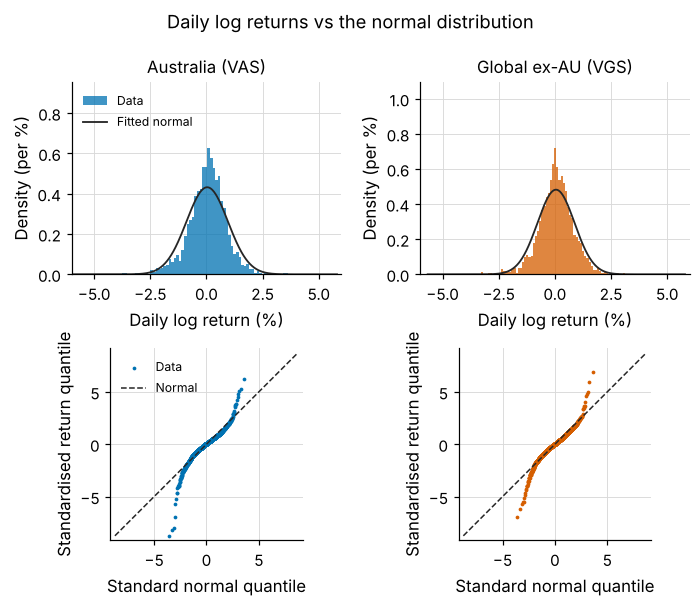

Histogram x-range is ±6%; daily returns outside it (shown in the QQ plots): {'AU': 4, 'GL': 0}


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.6))
qlim = 0
for j, k in enumerate(KEYS):
    x = 100 * daily[k]                                    # percent
    m, s = x.mean(), x.std(ddof=1)
    ax = axes[0, j]
    ax.hist(x, bins=120, density=True, color=cfg.COLORS[k], alpha=0.75, lw=0, label="Data")
    grid = np.linspace(x.min(), x.max(), 600)
    ax.plot(grid, stats.norm.pdf(grid, m, s), color="0.15", lw=1.2, label="Fitted normal")
    ax.set_xlim(-6, 6)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.45)
    ax.set_title(cfg.LABELS[k], fontsize=11)
    ax.set_xlabel("Daily log return (%)")
    ax.set_ylabel("Density (per %)")

    z = np.sort(((x - m) / s).to_numpy())
    theo = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
    ax = axes[1, j]
    ax.scatter(theo, z, s=6, color=cfg.COLORS[k], lw=0, label="Data")
    qlim = max(qlim, np.abs(z).max(), np.abs(theo).max())
    ax.set_xlabel("Standard normal quantile")
    ax.set_ylabel("Standardised return quantile")

out_of_range = {k: int(((100 * daily[k]).abs() > 6).sum()) for k in KEYS}
for ax in axes[1]:
    ax.plot([-qlim, qlim], [-qlim, qlim], ls="--", color="0.15", lw=1, label="Normal")
    ax.set_xlim(-qlim * 1.05, qlim * 1.05)
    ax.set_ylim(-qlim * 1.05, qlim * 1.05)
    ax.set_aspect("equal")
axes[0, 0].legend(loc="upper left", fontsize=8)
axes[1, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Daily log returns vs the normal distribution", fontsize=12)
fig.tight_layout()
gu.savefig(fig, "fig03_normality")
plt.show()
print(f"Histogram x-range is ±6%; daily returns outside it (shown in the QQ plots): {out_of_range}")

## 4. Independence and constant volatility — Fig 4

Sample autocorrelations of daily log returns (left) and of squared daily log returns (right) at lags
1–20 for each ETF. The shaded band is $\pm 1.96/\sqrt{n}$, the approximate 95% band for an i.i.d. series.

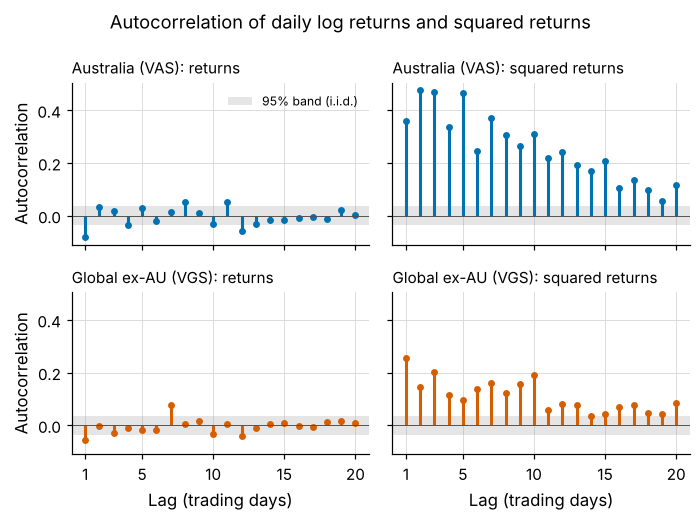

95% band: ±0.0356. Lags outside the band (of 20):
AU returns             4
AU squared returns    20
GL returns             3
GL squared returns    20


In [5]:
L = cfg.ACF_LAGS
n = len(daily)
band = 1.96 / np.sqrt(n)
lags = np.arange(1, L + 1)
acfs = {}
fig, axes = plt.subplots(2, 2, figsize=(6.5, 4.8), sharex=True, sharey=True)
for i, k in enumerate(KEYS):
    for j, (name, series) in enumerate([("returns", daily[k]), ("squared returns", daily[k] ** 2)]):
        a = acf(series, nlags=L, fft=True)[1:]
        acfs[(k, name)] = a
        ax = axes[i, j]
        ax.axhspan(-band, band, color="0.6", alpha=0.25, lw=0, label="95% band (i.i.d.)")
        ax.vlines(lags, 0, a, color=cfg.COLORS[k], lw=2)
        ax.plot(lags, a, "o", color=cfg.COLORS[k], ms=3.5)
        ax.axhline(0, color="0.3", lw=0.6)
        ax.set_title(f"{cfg.LABELS[k]}: {name}", fontsize=10, loc="left")
        if i == 1:
            ax.set_xlabel("Lag (trading days)")
        if j == 0:
            ax.set_ylabel("Autocorrelation")
axes[0, 0].set_xticks([1, 5, 10, 15, 20])
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle("Autocorrelation of daily log returns and squared returns", fontsize=12)
fig.tight_layout()
gu.savefig(fig, "fig04_acf")
plt.show()

acf_tab = pd.DataFrame({f"{k} {name}": a for (k, name), a in acfs.items()}, index=pd.Index(lags, name="lag"))
print(f"95% band: ±{band:.4f}. Lags outside the band (of {L}):")
print((acf_tab.abs() > band).sum().to_string())

## 5. Constant volatility — Fig 5

Rolling annualised volatility over a 63-trading-day window,
$\hat\sigma_t = \operatorname{sd}(X_{t-62},\dots,X_t)\sqrt{252}$, for both ETFs. Dashed lines are the
full-sample estimates.

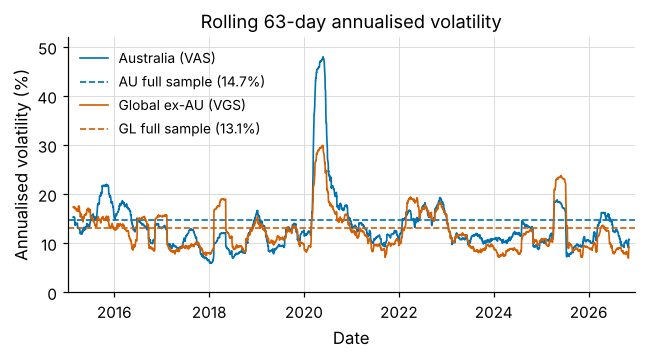

Full-sample annualised volatility: {'AU': 14.65, 'GL': 13.13} (%)
Rolling volatility range (%):
     min date of min    max date of max
AU  5.92  2018-01-09  47.97  2020-05-26
GL  6.98  2026-11-03  29.92  2020-05-26


In [6]:
W = cfg.ROLL_VOL_WINDOW
roll_vol = daily.rolling(W).std() * np.sqrt(cfg.TRADING_DAYS)
full_vol = daily.std() * np.sqrt(cfg.TRADING_DAYS)

fig, ax = plt.subplots(figsize=(6.0, 3.4))
for k in KEYS:
    ax.plot(roll_vol.index, 100 * roll_vol[k], color=cfg.COLORS[k], lw=1.1, label=cfg.LABELS[k])
    ax.axhline(100 * full_vol[k], color=cfg.COLORS[k], ls="--", lw=1.1,
               label=f"{k} full sample ({100 * full_vol[k]:.1f}%)")
ax.set_title(f"Rolling {W}-day annualised volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualised volatility (%)")
ax.set_ylim(0, 52)
ax.legend(loc="upper left", fontsize=9)
ax.margins(x=0.01)
fig.tight_layout()
gu.savefig(fig, "fig05_rolling_vol")
plt.show()

rv = roll_vol.dropna()
print("Full-sample annualised volatility:", (100 * full_vol).round(2).to_dict(), "(%)")
print("Rolling volatility range (%):")
print(pd.DataFrame({"min": 100 * rv.min(), "date of min": rv.idxmin().dt.date,
                    "max": 100 * rv.max(), "date of max": rv.idxmax().dt.date}).round(2))

## 6. Constant correlation — Fig 6

Rolling correlation between AU and GL daily log returns over a 126-trading-day window. The dashed line is
the full-sample correlation $\hat\rho$.

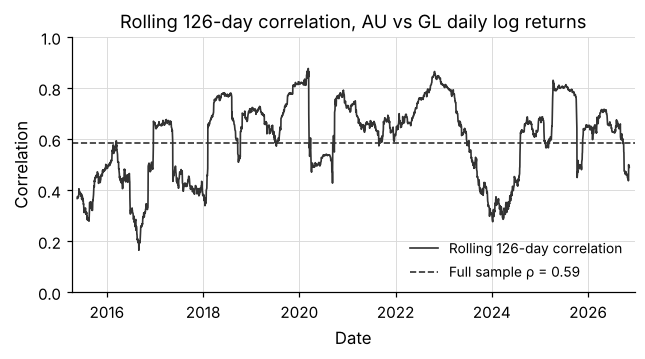

Full-sample rho = 0.5855; rolling range 0.165 (2016-08-31) to 0.878 (2020-03-09)


In [7]:
W = cfg.ROLL_CORR_WINDOW
roll_corr = daily["AU"].rolling(W).corr(daily["GL"])
rho = daily["AU"].corr(daily["GL"])

fig, ax = plt.subplots(figsize=(6.0, 3.4))
ax.plot(roll_corr.index, roll_corr, color="0.2", lw=1.1, label=f"Rolling {W}-day correlation")
ax.axhline(rho, color="0.2", ls="--", lw=1.1, label=f"Full sample ρ = {rho:.2f}")
ax.set_title(f"Rolling {W}-day correlation, AU vs GL daily log returns")
ax.set_xlabel("Date")
ax.set_ylabel("Correlation")
ax.set_ylim(0, 1)
ax.legend(loc="lower right", fontsize=9)
ax.margins(x=0.01)
fig.tight_layout()
gu.savefig(fig, "fig06_rolling_corr")
plt.show()

rc = roll_corr.dropna()
print(f"Full-sample rho = {rho:.4f}; rolling range {rc.min():.3f} ({rc.idxmin().date()}) "
      f"to {rc.max():.3f} ({rc.idxmax().date()})")

## 7. Scaling with horizon — variance ratios

Under GBM the variance of a $q$-day log return is $q$ times the daily variance, so the variance ratio
$\mathrm{VR}(q) = \operatorname{Var}(X_{t}+\dots+X_{t-q+1}) / (q\operatorname{Var}(X_t))$ equals 1.
The table uses overlapping $q$-day sums (Lo and MacKinlay, 1988) with the heteroskedasticity-robust
$z^*$ statistic, which stays valid when volatility changes over time.

In [8]:
vr_rows = []
for k in KEYS:
    for q in cfg.VR_HORIZONS:
        vr, z, p = gu.variance_ratio(daily[k], q)
        vr_rows.append({"ETF": k, "q (days)": q, "VR(q)": vr, "z*": z, "p-value": p})
vr_tab = pd.DataFrame(vr_rows).set_index(["ETF", "q (days)"])
vr_tab.to_csv(gu.TAB_DIR / "variance_ratios.csv")
vr_tab.unstack("ETF").swaplevel(axis=1).sort_index(axis=1).to_latex(
    gu.TAB_DIR / "variance_ratios.tex", float_format="%.3f", multicolumn_format="c",
    caption="Lo--MacKinlay variance ratios of daily log returns with heteroskedasticity-robust $z^*$.",
    label="tab:vr")
vr_tab.round(3)

VR(q)     z*  p-value
ETF q (days)                       
AU  2         0.919 -2.086    0.037
    5         0.912 -0.975    0.330
    10        0.942 -0.419    0.675
    21        0.928 -0.363    0.717
    63        0.752 -0.855    0.393
GL  2         0.945 -1.797    0.072
    5         0.882 -1.885    0.059
    10        0.863 -1.483    0.138
    21        0.839 -1.215    0.224
    63        0.748 -1.204    0.229

## 8. Summary of the checks

One row per GBM implication, with the statistic and p-value printed from the results above. A p-value
below 0.05 means the implication is rejected at the 5% level.

In [9]:
def p(f, k, row):
    return table2.loc[row, (f, k)]

summ = []
for k in KEYS:
    summ += [
        {"ETF": k, "implication": "normal daily returns", "statistic": "Jarque-Bera",
         "p-value": p("daily", k, "JB p-value")},
        {"ETF": k, "implication": "normal monthly returns", "statistic": "Jarque-Bera",
         "p-value": p("monthly", k, "JB p-value")},
        {"ETF": k, "implication": "independent daily returns", "statistic": f"Ljung-Box({cfg.LB_LAGS['daily']})",
         "p-value": p("daily", k, "LB p-value (returns)")},
        {"ETF": k, "implication": "constant volatility", "statistic": f"Ljung-Box({cfg.LB_LAGS['daily']}) on squares",
         "p-value": p("daily", k, "LB p-value (squared returns)")},
        {"ETF": k, "implication": "variance linear in horizon", "statistic": "VR(21)",
         "p-value": vr_tab.loc[(k, 21), "p-value"]},
    ]
summary = pd.DataFrame(summ)
summary["reject at 5%"] = summary["p-value"] < 0.05
summary.style.format({"p-value": lambda v: "<0.001" if v < 0.001 else f"{v:.3f}"}).hide(axis="index")

ETF,implication,statistic,p-value,reject at 5%
AU,normal daily returns,Jarque-Bera,<0.001,True
AU,normal monthly returns,Jarque-Bera,<0.001,True
AU,independent daily returns,Ljung-Box(20),<0.001,True
AU,constant volatility,Ljung-Box(20) on squares,<0.001,True
AU,variance linear in horizon,VR(21),0.717,False
GL,normal daily returns,Jarque-Bera,<0.001,True
GL,normal monthly returns,Jarque-Bera,0.125,False
GL,independent daily returns,Ljung-Box(20),0.002,True
GL,constant volatility,Ljung-Box(20) on squares,<0.001,True
GL,variance linear in horizon,VR(21),0.224,False
